# Bölüm 30 Uygulaması: Kötü Amaçlı Örnekler (Adversarial Examples)

**Kaynak:** Christoph Molnar, *Interpretable Machine Learning*, 3. baskı, Bölüm 30
**Hazırlayan:** Talha Karaca

Bu notebook, bölümde anlatılan saldırı yöntemlerini küçük ve basit bir veri seti üzerinde canlı olarak uygular. Kullanılan veri seti, scikit-learn ile birlikte gelen **8×8 piksellik el yazısı rakamlar** (`load_digits`, 1.797 görüntü, 10 sınıf) veri setidir. İnternet bağlantısı ya da GPU gerekmez; tüm hücreler sıradan bir dizüstü bilgisayarda birkaç dakikada çalışır.

| # | Bölüm | Kitaptaki karşılığı |
|---|-------|---------------------|
| 0 | Veri ve model | – |
| 1 | Hızlı gradyan işaret yöntemi (FGSM) | Rahatsız Edilmiş Panda |
| 2 | Hedefli saldırı: kutu kısıtlamalı L-BFGS | Köpeğimde Bir Terslik Var |
| 3 | 1-piksel saldırısı (diferansiyel evrim) | Bir Denizanası… Hayır, Bekle. Bir Küvet |
| 4 | Kara kutu saldırısı (vekil model) | Gözü Bağlı Düşman |
| 5 | Savunma: adversarial eğitim ve kedi-fare oyunu | Siber Güvenlik Perspektifi |

Tüm grafikler ayrıca `gorseller/` klasörüne PNG olarak kaydedilir.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.optimize import minimize, differential_evolution
from sklearn.datasets import load_digits
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

GORSEL = Path("gorseller")
GORSEL.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.titlesize": 10})

def kaydet(fig, ad):
    fig.savefig(GORSEL / f"{ad}.png", bbox_inches="tight", dpi=150)

def goster(ax, img, baslik="", cmap="gray_r", **kw):
    ax.imshow(np.asarray(img).reshape(8, 8), cmap=cmap, **kw)
    ax.set_title(baslik)
    ax.set_xticks([]); ax.set_yticks([])

## 0. Veri ve model

Piksel değerleri 0–16 aralığındadır; 16'ya bölerek **[0, 1]** aralığına getiriyoruz. Böylece bölümdeki "piksel değerleri 0 ile 1 arasında kalmalı" kısıtı doğrudan geçerli olur.

Veriyi üçe ayırıyoruz:

- **eğitim** kümesi: modeli eğitmek için,
- **test** kümesi: saldırıları değerlendirmek için,
- **saldırgan havuzu**: kara kutu saldırısında saldırganın elindeki, eğitim verisinden *bağımsız* birkaç görüntü (Bölüm 4).

Eğitim: 1078  ·  Test: 503  ·  Saldırgan havuzu: 216


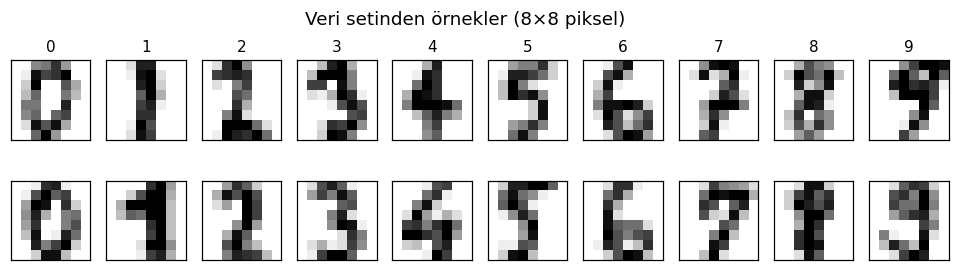

In [2]:
digits = load_digits()
X = (digits.images / 16.0).astype(np.float32)   # (1797, 8, 8), değerler [0, 1]
y = digits.target

X_egitim, X_kalan, y_egitim, y_kalan = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=SEED)
X_test, X_saldirgan, y_test, y_saldirgan = train_test_split(
    X_kalan, y_kalan, test_size=0.3, stratify=y_kalan, random_state=SEED)

print(f"Eğitim: {len(X_egitim)}  ·  Test: {len(X_test)}  ·  Saldırgan havuzu: {len(X_saldirgan)}")

fig, axes = plt.subplots(2, 10, figsize=(11, 2.6))
for rakam in range(10):
    ornekler = np.where(y_egitim == rakam)[0][:2]
    for satir, i in enumerate(ornekler):
        goster(axes[satir, rakam], X_egitim[i], str(rakam) if satir == 0 else "")
fig.suptitle("Veri setinden örnekler (8×8 piksel)", y=1.02)
kaydet(fig, "00_veri_ornekleri")
plt.show()

Saldırıların hedefi olarak küçük bir **evrişimli sinir ağı (CNN)** eğitiyoruz. Gradyan tabanlı saldırılar (FGSM, L-BFGS) bu modelin gradyanlarını kullanacak.

Test doğruluğu: 0.976


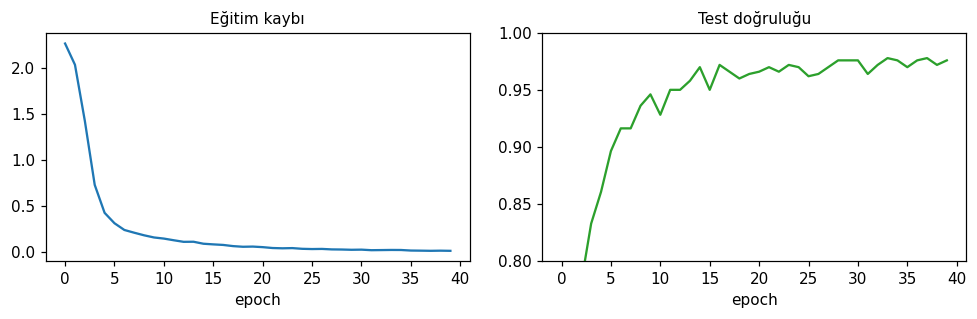

In [3]:
class KucukCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1 = nn.Conv2d(1, 16, 3, padding=1)
        self.c2 = nn.Conv2d(16, 32, 3, padding=1)
        self.fc1 = nn.Linear(32 * 4 * 4, 64)
        self.fc2 = nn.Linear(64, 10)

    def forward(self, x):
        x = x.reshape(-1, 1, 8, 8)
        x = F.relu(self.c1(x))
        x = F.max_pool2d(F.relu(self.c2(x)), 2)
        x = F.relu(self.fc1(x.flatten(1)))
        return self.fc2(x)

T = lambda a: torch.tensor(a, dtype=torch.float32)
Xtr, ytr = T(X_egitim), torch.tensor(y_egitim)
Xte, yte = T(X_test), torch.tensor(y_test)

@torch.no_grad()
def dogruluk(model, X, y):
    model.eval()
    return (model(X).argmax(1) == y).float().mean().item()

@torch.no_grad()
def tahmin(model, x):
    # Tek bir görüntü için (sınıf, olasılık) döndürür.
    model.eval()
    p = F.softmax(model(x.reshape(1, 8, 8)), dim=1)[0]
    return int(p.argmax()), float(p.max())

def egit(model, X, y, epoch=40, bs=64, lr=1e-3, adv_eps=None):
    # adv_eps verilirse her mini-yığına FGSM örnekleri eklenir (adversarial eğitim, Bölüm 5).
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    gecmis = []
    for _ in range(epoch):
        model.train()
        perm = torch.randperm(len(X))
        toplam = 0.0
        for i in range(0, len(X), bs):
            idx = perm[i:i + bs]
            xb, yb = X[idx], y[idx]
            if adv_eps is not None:
                xb = torch.cat([xb, fgsm(model, xb, yb, adv_eps)])
                yb = torch.cat([yb, yb])
            opt.zero_grad()
            kayip = F.cross_entropy(model(xb), yb)
            kayip.backward()
            opt.step()
            toplam += kayip.item() * len(idx)
        gecmis.append((toplam / len(X), dogruluk(model, Xte, yte)))
    return gecmis

model = KucukCNN()
gecmis = egit(model, Xtr, ytr)
print(f"Test doğruluğu: {dogruluk(model, Xte, yte):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot([g[0] for g in gecmis]); ax[0].set_title("Eğitim kaybı"); ax[0].set_xlabel("epoch")
ax[1].plot([g[1] for g in gecmis], color="tab:green"); ax[1].set_title("Test doğruluğu"); ax[1].set_xlabel("epoch")
ax[1].set_ylim(0.8, 1.0)
fig.tight_layout(); kaydet(fig, "01_egitim"); plt.show()

Model temiz test verisinde çok yüksek doğruluğa ulaşır. Bölümde vurgulandığı gibi, test doğruluğu %100'e yakın olan bir modeli kandıran örnekler de bulunabilir.

## 1. Hızlı gradyan işaret yöntemi (FGSM)

Goodfellow vd. (2015), orijinal görüntüyü kaybı artıran yönde, her piksele küçük bir $\epsilon$ ekleyerek ya da çıkararak değiştirir:

$$\mathbf{x}^\prime = \mathbf{x} + \epsilon \cdot \text{sign}\left(\nabla_{\mathbf{x}} J(\boldsymbol{\theta}, \mathbf{x}, y)\right)$$

Gradyanın yalnızca **işaretini** kullanırız: Bir pikseli artırmak kaybı artırıyorsa +1, azaltmak kaybı artırıyorsa −1. Tek bir gradyan hesabı yeterlidir; yöntem bu yüzden "hızlı"dır.

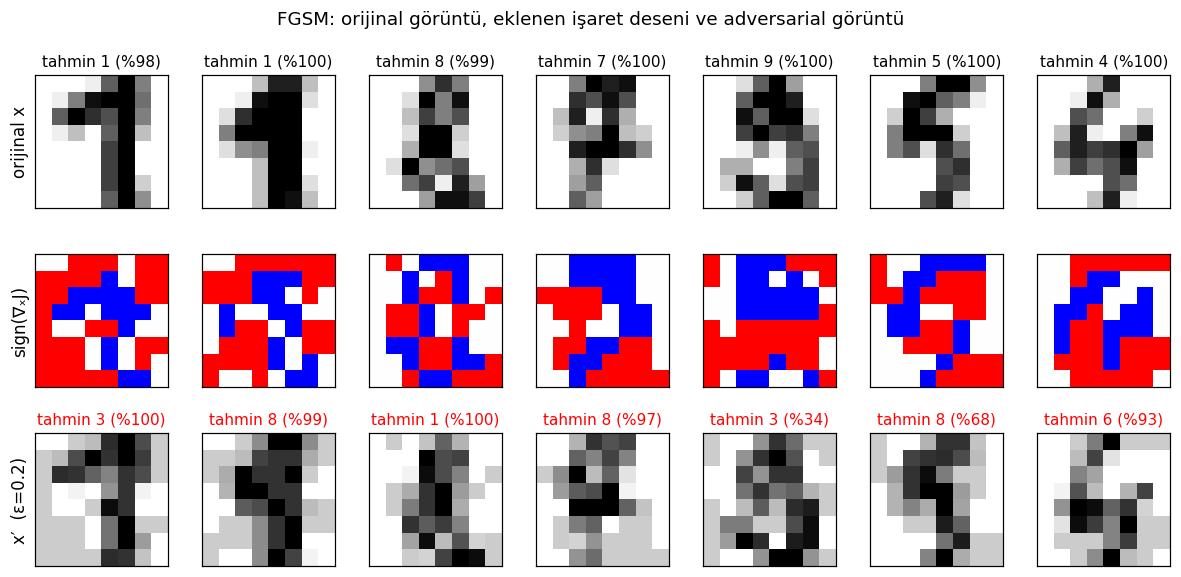

In [4]:
def fgsm(model, x, y, eps):
    x = x.clone().detach().requires_grad_(True)
    kayip = F.cross_entropy(model(x), y)
    grad, = torch.autograd.grad(kayip, x)
    return (x + eps * grad.sign()).clamp(0, 1).detach()

EPS = 0.2
dogru = (model(Xte).argmax(1) == yte).nonzero().flatten()
secilen = dogru[:7]
x_adv = fgsm(model, Xte[secilen], yte[secilen], EPS)

fig, axes = plt.subplots(3, 7, figsize=(11, 5.2))
for j, i in enumerate(secilen):
    s0, p0 = tahmin(model, Xte[i])
    s1, p1 = tahmin(model, x_adv[j])
    goster(axes[0, j], Xte[i], f"tahmin {s0} (%{100*p0:.0f})")
    goster(axes[1, j], (x_adv[j] - Xte[i]).sign(), "", cmap="bwr", vmin=-1, vmax=1)
    renk = "red" if s1 != s0 else "black"
    goster(axes[2, j], x_adv[j], f"tahmin {s1} (%{100*p1:.0f})")
    axes[2, j].title.set_color(renk)
for ax, etiket in zip(axes[:, 0], ["orijinal x", "sign(∇ₓJ)", f"x′  (ε={EPS})"]):
    ax.set_ylabel(etiket, fontsize=11)
fig.suptitle("FGSM: orijinal görüntü, eklenen işaret deseni ve adversarial görüntü", y=1.0)
fig.tight_layout(); fig.subplots_adjust(hspace=0.35); kaydet(fig, "02_fgsm_ornekler"); plt.show()

Kırmızı başlıklar modelin yanıldığı görüntülerdir; model çoğu zaman yanlış sınıfı yüksek güvenle tahmin eder.

FGSM'in etkisini aynı büyüklükteki **rastgele gürültüyle** karşılaştırıyoruz. Rastgele gürültüde her piksele yine ±ε eklenir, işaretler rastgele seçilir.

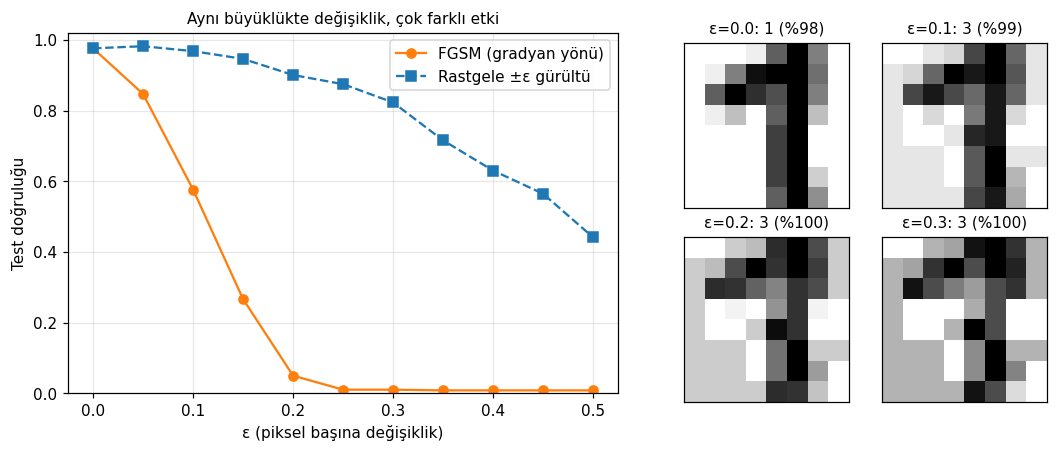

ε=0.1:  FGSM doğruluğu 0.58  ·  rastgele gürültü doğruluğu 0.97
ε=0.2:  FGSM doğruluğu 0.05  ·  rastgele gürültü doğruluğu 0.90
ε=0.3:  FGSM doğruluğu 0.01  ·  rastgele gürültü doğruluğu 0.82


In [5]:
eps_listesi = np.round(np.arange(0, 0.51, 0.05), 2)
torch.manual_seed(SEED)
acc_fgsm = [dogruluk(model, fgsm(model, Xte, yte, e), yte) for e in eps_listesi]
acc_gurultu = [dogruluk(model, (Xte + e * torch.randn_like(Xte).sign()).clamp(0, 1), yte)
               for e in eps_listesi]

fig = plt.figure(figsize=(10, 4.2))
ax = fig.add_axes([0.07, 0.12, 0.5, 0.78])
ax.plot(eps_listesi, acc_fgsm, "o-", color="tab:orange", label="FGSM (gradyan yönü)")
ax.plot(eps_listesi, acc_gurultu, "s--", color="tab:blue", label="Rastgele ±ε gürültü")
ax.set_xlabel("ε (piksel başına değişiklik)"); ax.set_ylabel("Test doğruluğu")
ax.set_ylim(0, 1.02); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Aynı büyüklükte değişiklik, çok farklı etki")
ornek = Xte[secilen[0]]
for k, e in enumerate([0.0, 0.1, 0.2, 0.3]):
    a = fig.add_axes([0.63 + (k % 2) * 0.18, 0.52 - (k // 2) * 0.42, 0.15, 0.36])
    xa = fgsm(model, ornek[None], yte[secilen[0]][None], e)[0]
    s, p = tahmin(model, xa)
    goster(a, xa, f"ε={e}: {s} (%{100*p:.0f})")
kaydet(fig, "03_fgsm_eps_egrisi"); plt.show()

for e, a1, a2 in zip(eps_listesi, acc_fgsm, acc_gurultu):
    if e in (0.1, 0.2, 0.3):
        print(f"ε={e}:  FGSM doğruluğu {a1:.2f}  ·  rastgele gürültü doğruluğu {a2:.2f}")

Rastgele gürültü doğruluğu çok az değiştirir. FGSM doğruluğu hızla düşürür. Saldırının gücü, değişikliğin yönünün modelin gradyanına göre seçilmesinden gelir. Bölümde anlatıldığı gibi, ağ piksel yoğunluğu ile sınıf skoru arasındaki ilişkiyi yerel olarak doğrusala yakın ele alır; tüm pikseller gradyan yönünde birlikte itildiğinde skorlar büyük ölçüde değişir.

> Not: 8×8 görüntülerde her piksel görüntünün 1/64'üdür; bu yüzden büyük ε değerlerinde değişiklik gözle de seçilebilir. Yüksek çözünürlüklü görüntülerde (örneğin ImageNet) çok daha küçük, gözle görülmeyen ε değerleri yeterlidir.

## 2. Hedefli saldırı: kutu kısıtlamalı L-BFGS

Szegedy vd. (2014), modeli **belirli bir hedef sınıfa** ($l$) yönlendiren en küçük değişikliği arar:

$$\text{loss}(\hat{f}(\mathbf{x}+\mathbf{r}), l) + c \cdot |\mathbf{r}|$$

Pikseller [0, 1] aralığında kalmalıdır; bu yüzden problem **kutu kısıtlamalı L-BFGS** (`scipy`'deki `L-BFGS-B`) ile çözülür. Burada $|\mathbf{r}|$ için türevlenebilir olması adına Öklid normunun karesini kullanıyoruz. $c$ büyüdükçe değişiklik küçülür; $c$'yi büyükten küçüğe deneyip saldırının başarılı olduğu ilk değeri seçiyoruz.

Kitaptaki "hepsi devekuşu" şeklinin bir benzerini üretelim: Her rakamdan bir görüntü alıp hepsini **"3"** olarak sınıflandırtalım.

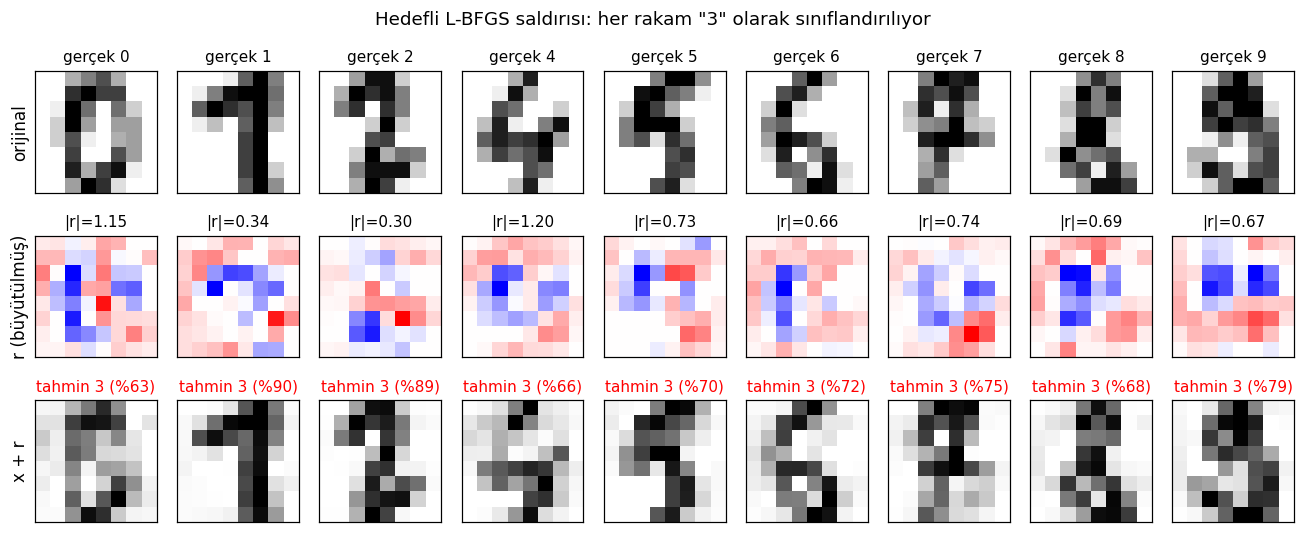

In [6]:
def lbfgs_saldirisi(model, x, hedef, c_listesi=(3.0, 1.0, 0.3, 0.1, 0.03, 0.01)):
    model.eval()
    x0 = x.flatten().numpy().astype(np.float64)
    x0_t = torch.tensor(x0, dtype=torch.float32)
    hedef_t = torch.tensor([hedef])
    for c in c_listesi:
        def amac(xp):
            xp_t = torch.tensor(xp, dtype=torch.float32, requires_grad=True)
            toplam = F.cross_entropy(model(xp_t), hedef_t) + c * ((xp_t - x0_t) ** 2).sum()
            g, = torch.autograd.grad(toplam, xp_t)
            return toplam.item(), g.numpy().astype(np.float64)
        sonuc = minimize(amac, x0, jac=True, method="L-BFGS-B", bounds=[(0, 1)] * 64)
        x_yeni = torch.tensor(sonuc.x, dtype=torch.float32).reshape(8, 8)
        if tahmin(model, x_yeni)[0] == hedef:
            return x_yeni, c
    return x_yeni, None

HEDEF = 3
kaynaklar = [int(dogru[(yte[dogru] == r).nonzero()[0, 0]]) for r in range(10) if r != HEDEF]

fig, axes = plt.subplots(3, 9, figsize=(12, 4.8))
for j, i in enumerate(kaynaklar):
    x_h, c = lbfgs_saldirisi(model, Xte[i], HEDEF)
    r = x_h - Xte[i]
    s1, p1 = tahmin(model, x_h)
    goster(axes[0, j], Xte[i], f"gerçek {int(yte[i])}")
    m = float(r.abs().max()) or 1.0
    goster(axes[1, j], r, f"|r|={float(r.norm()):.2f}", cmap="bwr", vmin=-m, vmax=m)
    goster(axes[2, j], x_h, f"tahmin {s1} (%{100*p1:.0f})")
    axes[2, j].title.set_color("red" if s1 == HEDEF else "black")
for ax, etiket in zip(axes[:, 0], ["orijinal", "r (büyütülmüş)", "x + r"]):
    ax.set_ylabel(etiket, fontsize=11)
fig.suptitle(f"Hedefli L-BFGS saldırısı: her rakam \"{HEDEF}\" olarak sınıflandırılıyor", y=1.0)
fig.tight_layout(); fig.subplots_adjust(hspace=0.35); kaydet(fig, "04_lbfgs_hedefli"); plt.show()

Orta satır, eklenen değişikliği (kendi ölçeğinde büyütülmüş olarak) gösterir. Değişiklik görüntünün tamamına yayılmış, düşük genlikli bir desendir ve model her rakamı hedef sınıfa atar. Bu formülasyon karşıt açıklamalarda kullanılan kayıp fonksiyonuyla neredeyse aynıdır; buradaki amaç modeli kandırmaktır.

## 3. 1-piksel saldırısı (diferansiyel evrim)

Su vd. (2019) şunu sorar: **Yalnızca tek bir pikseli** değiştirerek modeli kandırabilir miyiz? Bu saldırı gradyan kullanmaz, yalnızca modelin tahmin olasılıklarına bakar.

Her aday çözüm bir piksel değişikliğidir. Gri tonlamalı görüntülerde aday 3 elemanlıdır: (satır, sütun, yeni değer). Yeni adaylar diferansiyel evrimle üretilir:

$$\mathbf{x}_{g+1}^{(i)} = \mathbf{x}_g^{(r1)} + F \cdot (\mathbf{x}_g^{(r2)}- \mathbf{x}_g^{(r3)})$$

Kitaptaki gibi $F = 0{,}5$ ve yaklaşık 400 aday kullanıyoruz. Amaç, **gerçek sınıfın olasılığını en aza indirmek**; model yanlış sınıfı tahmin ettiği anda arama durur.

In [7]:
@torch.no_grad()
def tek_piksel_saldirisi(model, x, y_gercek, maxiter=40, seed=SEED):
    model.eval()

    def uygula(adaylar):                       # adaylar: (3, N)
        N = adaylar.shape[1]
        xs = x.repeat(N, 1, 1)
        r = np.clip(adaylar[0].astype(int), 0, 7)
        s = np.clip(adaylar[1].astype(int), 0, 7)
        xs[torch.arange(N), r, s] = torch.tensor(adaylar[2], dtype=torch.float32)
        return xs

    def amac(adaylar):                         # gerçek sınıfın olasılığı (küçültülür)
        adaylar = adaylar.reshape(3, -1)
        return F.softmax(model(uygula(adaylar)), dim=1)[:, y_gercek].numpy()

    def dur(intermediate_result):
        return int(model(uygula(intermediate_result.x.reshape(3, 1))).argmax(1)) != y_gercek

    sonuc = differential_evolution(
        amac, bounds=[(0, 7.999), (0, 7.999), (0, 1)], popsize=133,   # 133 × 3 ≈ 400 aday
        mutation=0.5, recombination=1.0, maxiter=maxiter, seed=seed,
        vectorized=True, updating="deferred", polish=False, callback=dur)
    x_yeni = uygula(sonuc.x.reshape(3, 1))[0]
    return x_yeni, (int(sonuc.x[0]), int(sonuc.x[1]))

N_DENEME = 100
basarili = []
for i in dogru[:N_DENEME]:
    x_yeni, konum = tek_piksel_saldirisi(model, Xte[i], int(yte[i]))
    s1, p1 = tahmin(model, x_yeni)
    if s1 != int(yte[i]):
        basarili.append((int(i), x_yeni, konum, s1, p1))

print(f"1-piksel saldırısı başarı oranı: {len(basarili)}/{N_DENEME} = %{100*len(basarili)/N_DENEME:.0f}")

1-piksel saldırısı başarı oranı: 33/100 = %33


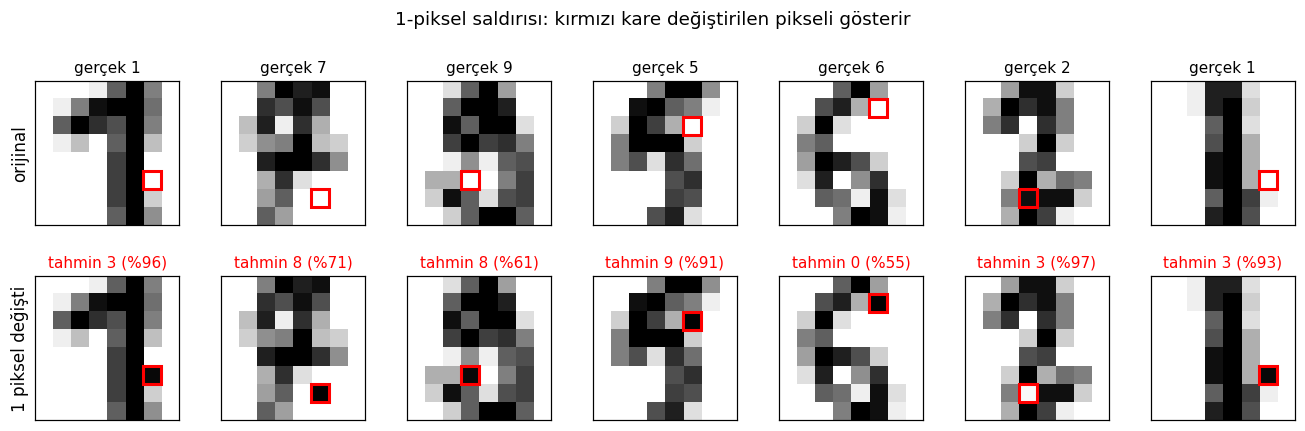

In [8]:
from matplotlib.patches import Rectangle

gosterilecek = basarili[:7]
fig, axes = plt.subplots(2, len(gosterilecek), figsize=(1.6 * len(gosterilecek) + 1, 3.8), squeeze=False)
for j, (i, x_yeni, (r, s), s1, p1) in enumerate(gosterilecek):
    goster(axes[0, j], Xte[i], f"gerçek {int(yte[i])}")
    goster(axes[1, j], x_yeni, f"tahmin {s1} (%{100*p1:.0f})")
    axes[1, j].title.set_color("red")
    for ax in axes[:, j]:
        ax.add_patch(Rectangle((s - 0.5, r - 0.5), 1, 1, fill=False, ec="red", lw=2))
axes[0, 0].set_ylabel("orijinal", fontsize=11)
axes[1, 0].set_ylabel("1 piksel değişti", fontsize=11)
fig.suptitle("1-piksel saldırısı: kırmızı kare değiştirilen pikseli gösterir", y=1.02)
fig.tight_layout(); fig.subplots_adjust(hspace=0.35); kaydet(fig, "05_tek_piksel"); plt.show()

8×8 görüntüde tek piksel, görüntünün 1/64'üdür. Saldırı bu kadar küçük bir değişiklikle görüntülerin bir kısmında başarılı olur. Saldırı yalnızca tahmin olasılıklarını kullandığı için **modelden bağımsızdır**: İç yapısını bilmediğimiz bir modele de uygulanabilir.

## 4. Kara kutu saldırısı (vekil model)

Bu kez hedef model bir **rastgele orman** olsun. Rastgele ormanın gradyanı yoktur; üstelik saldırgan yalnızca modele görüntü gönderip **etiket** alabilir (bir web API'si gibi). Ne model parametrelerine ne de eğitim verisine erişimi vardır.

Papernot vd. (2017)'nin adımları:

1. Aynı alandan birkaç görüntüyle başla (burada saldırgan havuzundan 100 görüntü).
2. Bu görüntüler için kara kutudan etiket al.
3. Bu etiketlerle bir vekil model (küçük bir sinir ağı) eğit.
4. Vekilin gradyanını kullanarak yeni sentetik görüntüler üret (Jacobian tabanlı veri artırma) ve kümeye ekle.
5. 2–4. adımları birkaç tur tekrarla.
6. Vekil model üzerinde FGSM ile adversarial örnekler üret.
7. Bu örneklerle kara kutuya saldır.

In [9]:
kara_kutu = RandomForestClassifier(n_estimators=200, random_state=SEED)
kara_kutu.fit(X_egitim.reshape(len(X_egitim), -1), y_egitim)
SORGU = {"sayi": 0}

def kara_kutuya_sor(x):
    # Saldırganın tek erişimi: görüntü gönder, etiket al.
    SORGU["sayi"] += len(x)
    return torch.tensor(kara_kutu.predict(x.reshape(len(x), -1).numpy()))

print(f"Kara kutunun (rastgele orman) test doğruluğu: "
      f"{(kara_kutu.predict(X_test.reshape(len(X_test), -1)) == y_test).mean():.3f}")

class Vekil(nn.Module):
    def __init__(self):
        super().__init__()
        self.ag = nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 10))
    def forward(self, x):
        return self.ag(x.reshape(-1, 64))

def jacobian_artirma(vekil, X, etiket, lam=0.1):
    X = X.clone().requires_grad_(True)
    secili = vekil(X).gather(1, etiket.view(-1, 1)).sum()
    g, = torch.autograd.grad(secili, X)
    return (X + lam * g.sign()).clamp(0, 1).detach()

KK_TEST = kara_kutu.predict(X_test.reshape(len(X_test), -1))   # yalnızca değerlendirme için

def vekil_olustur(n_baslangic, turlar=5, yazdir=False):
    S = T(X_saldirgan[:n_baslangic])
    for tur in range(turlar):
        etiket = kara_kutuya_sor(S)                         # 2. adım
        torch.manual_seed(SEED)
        vekil = Vekil()                                     # 3. adım
        opt = torch.optim.Adam(vekil.parameters(), lr=1e-3)
        for _ in range(150):
            vekil.train(); opt.zero_grad()
            F.cross_entropy(vekil(S), etiket).backward(); opt.step()
        vekil.eval()
        with torch.no_grad():
            u = (vekil(Xte).argmax(1).numpy() == KK_TEST).mean()
        if yazdir:
            print(f"Tur {tur}: vekilin veri kümesi {len(S):4d} görüntü · kara kutuyla uyum {u:.2f}")
        if tur < turlar - 1:                                # 4. adım
            S = torch.cat([S, jacobian_artirma(vekil, S, etiket)])
    return vekil, u

vekil, _ = vekil_olustur(100, yazdir=True)
VEKIL_SORGU = SORGU["sayi"]
print(f"Vekili eğitmek için yapılan kara kutu sorgusu: {VEKIL_SORGU}")

Kara kutunun (rastgele orman) test doğruluğu: 0.966
Tur 0: vekilin veri kümesi  100 görüntü · kara kutuyla uyum 0.90
Tur 1: vekilin veri kümesi  200 görüntü · kara kutuyla uyum 0.89


Tur 2: vekilin veri kümesi  400 görüntü · kara kutuyla uyum 0.88
Tur 3: vekilin veri kümesi  800 görüntü · kara kutuyla uyum 0.89


Tur 4: vekilin veri kümesi 1600 görüntü · kara kutuyla uyum 0.88
Vekili eğitmek için yapılan kara kutu sorgusu: 3100


Bu küçük veri setinde Jacobian tabanlı veri artırma turları uyumu belirgin biçimde artırmaz; vekil 100 gerçek görüntüyle kara kutunun kararlarının büyük kısmını taklit eder. Vekilin kalitesini belirleyen, saldırganın elindeki **gerçek görüntü sayısıdır**. Bunu görmek için aynı yöntemi farklı sayıda başlangıç görüntüsüyle tekrarlayıp hem uyumu hem de saldırı sonrası kara kutunun doğruluğunu ölçüyoruz (ε = 0,2).

In [10]:
y_kk = kara_kutuya_sor(Xte)                     # saldırgan gerçek etiketleri de bilmez
dogru_kk = lambda Xa: (kara_kutu.predict(Xa.reshape(len(Xa), -1).numpy()) == y_test).mean()

n_listesi = [10, 25, 50, 100, 200]
deney = []
for n in n_listesi:
    v, u = vekil_olustur(n)
    deney.append((u, dogru_kk(fgsm(v, Xte, y_kk, 0.2))))

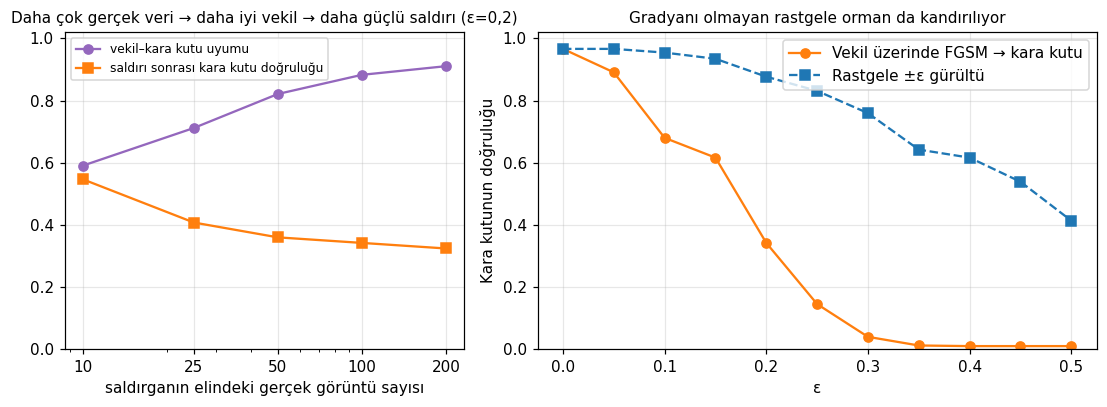

ε=0.2: aktarılan saldırı sonrası doğruluk 0.34 · rastgele gürültüyle 0.88
ε=0.3: aktarılan saldırı sonrası doğruluk 0.04 · rastgele gürültüyle 0.76


In [11]:
torch.manual_seed(SEED)
acc_transfer = [dogru_kk(fgsm(vekil, Xte, y_kk, e)) for e in eps_listesi]
acc_kk_gurultu = [dogru_kk((Xte + e * torch.randn_like(Xte).sign()).clamp(0, 1)) for e in eps_listesi]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
ax[0].plot(n_listesi, [d[0] for d in deney], "o-", color="tab:purple", label="vekil–kara kutu uyumu")
ax[0].plot(n_listesi, [d[1] for d in deney], "s-", color="tab:orange", label="saldırı sonrası kara kutu doğruluğu")
ax[0].set_xscale("log"); ax[0].set_xticks(n_listesi); ax[0].set_xticklabels(n_listesi)
ax[0].set_xlabel("saldırganın elindeki gerçek görüntü sayısı"); ax[0].set_ylim(0, 1.02)
ax[0].set_title("Daha çok gerçek veri → daha iyi vekil → daha güçlü saldırı (ε=0,2)")
ax[0].grid(alpha=0.3); ax[0].legend(fontsize=8)
ax[1].plot(eps_listesi, acc_transfer, "o-", color="tab:orange", label="Vekil üzerinde FGSM → kara kutu")
ax[1].plot(eps_listesi, acc_kk_gurultu, "s--", color="tab:blue", label="Rastgele ±ε gürültü")
ax[1].set_xlabel("ε"); ax[1].set_ylabel("Kara kutunun doğruluğu"); ax[1].set_ylim(0, 1.02)
ax[1].set_title("Gradyanı olmayan rastgele orman da kandırılıyor"); ax[1].grid(alpha=0.3); ax[1].legend()
fig.tight_layout(); kaydet(fig, "06_kara_kutu"); plt.show()

for e, a1, a2 in zip(eps_listesi, acc_transfer, acc_kk_gurultu):
    if e in (0.2, 0.3):
        print(f"ε={e}: aktarılan saldırı sonrası doğruluk {a1:.2f} · rastgele gürültüyle {a2:.2f}")

Saldırgan rastgele ormanın içini görmez ve eğitim verisine erişmez; 100 gerçek görüntüyle başlayıp birkaç bin sorgu yapar. Vekil sinir ağında bulunan adversarial örnekler kara kutuya **aktarılır** ve doğruluğunu düşürür. Bu sonuç bölümdeki iki tespiti destekler:

- Adversarial örnekler farklı modellere aktarılabilir.
- Yöntem, karar ağaçları gibi gradyanı olmayan modellerde de çalışır. Modeli ve veriyi gizlemek tek başına yeterli bir savunma değildir.

## 5. Savunma: adversarial eğitim ve kedi-fare oyunu

Bölümde önerilen proaktif savunma, modeli adversarial örneklerle birlikte yeniden eğitmektir. Her mini-yığına o anki modele karşı üretilmiş FGSM örneklerini (ε = 0,2) ekleyerek ikinci bir CNN eğitiyoruz.

Ardından iki modeli iki farklı saldırıyla deniyoruz:

- **FGSM**: modelin eğitimde gördüğü saldırı,
- **PGD** (yinelemeli FGSM): küçük adımlarla 10 kez gradyan yönünde ilerleyip her adımda değişikliği ε kutusuna geri yansıtan, daha güçlü bir saldırı.

Temiz test doğruluğu · normal model: 0.976 · adversarial eğitimli model: 0.968


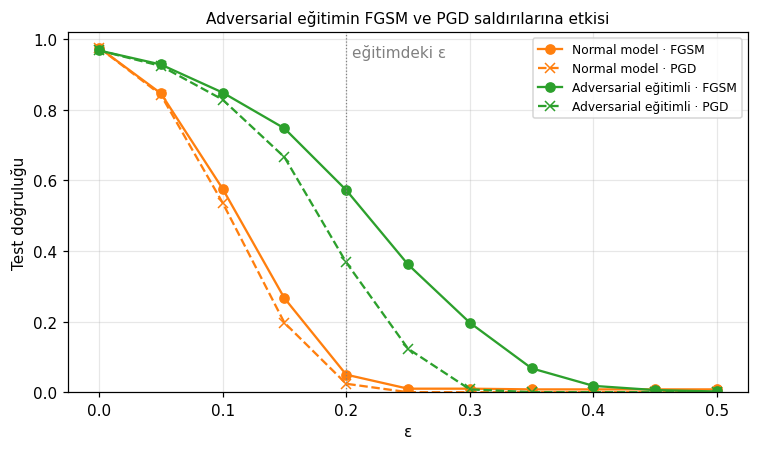

In [12]:
def pgd(model, x, y, eps, adim=10):
    alfa = eps / 4
    x_adv = x.clone().detach()
    for _ in range(adim):
        x_adv = fgsm(model, x_adv, y, alfa)
        x_adv = torch.min(torch.max(x_adv, x - eps), x + eps).clamp(0, 1)
    return x_adv

torch.manual_seed(SEED)
saglam = KucukCNN()
egit(saglam, Xtr, ytr, adv_eps=0.2)
print(f"Temiz test doğruluğu · normal model: {dogruluk(model, Xte, yte):.3f} · "
      f"adversarial eğitimli model: {dogruluk(saglam, Xte, yte):.3f}")

sonuclar = {}
for ad, m in [("Normal model", model), ("Adversarial eğitimli", saglam)]:
    sonuclar[ad] = {
        "FGSM": [dogruluk(m, fgsm(m, Xte, yte, e), yte) for e in eps_listesi],
        "PGD": [dogruluk(m, pgd(m, Xte, yte, e), yte) for e in eps_listesi],
    }

fig, ax = plt.subplots(figsize=(7, 4.2))
renk = {"Normal model": "tab:orange", "Adversarial eğitimli": "tab:green"}
for ad, d in sonuclar.items():
    ax.plot(eps_listesi, d["FGSM"], "o-", color=renk[ad], label=f"{ad} · FGSM")
    ax.plot(eps_listesi, d["PGD"], "x--", color=renk[ad], label=f"{ad} · PGD")
ax.axvline(0.2, color="gray", lw=0.8, ls=":"); ax.text(0.205, 0.95, "eğitimdeki ε", color="gray")
ax.set_xlabel("ε"); ax.set_ylabel("Test doğruluğu"); ax.set_ylim(0, 1.02); ax.grid(alpha=0.3)
ax.set_title("Adversarial eğitimin FGSM ve PGD saldırılarına etkisi")
ax.legend(fontsize=8)
fig.tight_layout(); kaydet(fig, "07_savunma"); plt.show()

Adversarial eğitim, modeli eğitimde gördüğü FGSM saldırısına karşı belirgin biçimde dayanıklı hâle getirir. Daha güçlü PGD saldırısı bu dayanıklılığın bir kısmını aşar; eğitimde kullanılan ε değerinin ötesinde koruma hızla azalır. Bölümde "kedi-fare oyunu" olarak anlatılan durum budur: Her yeni savunmaya karşı daha güçlü saldırılar geliştirilir.

## Özet

In [13]:
i02 = list(eps_listesi).index(0.2)
satirlar = [
    ("Temiz test doğruluğu (CNN)", f"{dogruluk(model, Xte, yte):.2f}"),
    ("FGSM, ε=0,2 sonrası doğruluk", f"{acc_fgsm[i02]:.2f}"),
    ("Rastgele ±0,2 gürültü sonrası doğruluk", f"{acc_gurultu[i02]:.2f}"),
    ("L-BFGS hedefli saldırı (9 rakam → 3)", "yukarıdaki şekil"),
    ("1-piksel saldırısı başarı oranı", f"%{100*len(basarili)/N_DENEME:.0f}"),
    ("Kara kutu (rastgele orman), aktarılan FGSM ε=0,2", f"{acc_transfer[i02]:.2f}"),
    ("Vekil için kara kutu sorgu sayısı", f"{VEKIL_SORGU}"),
    ("Adversarial eğitimli model, FGSM ε=0,2", f"{sonuclar['Adversarial eğitimli']['FGSM'][i02]:.2f}"),
    ("Adversarial eğitimli model, PGD ε=0,2", f"{sonuclar['Adversarial eğitimli']['PGD'][i02]:.2f}"),
]
genislik = max(len(s[0]) for s in satirlar)
for ad, deger in satirlar:
    print(f"{ad:<{genislik}}  {deger}")

Temiz test doğruluğu (CNN)                        0.98
FGSM, ε=0,2 sonrası doğruluk                      0.05
Rastgele ±0,2 gürültü sonrası doğruluk            0.90
L-BFGS hedefli saldırı (9 rakam → 3)              yukarıdaki şekil
1-piksel saldırısı başarı oranı                   %33
Kara kutu (rastgele orman), aktarılan FGSM ε=0,2  0.34
Vekil için kara kutu sorgu sayısı                 3100
Adversarial eğitimli model, FGSM ε=0,2            0.57
Adversarial eğitimli model, PGD ε=0,2             0.37


**Çıkarımlar**

1. Temiz test verisindeki yüksek doğruluk modelin sağlam olduğunu göstermez.
2. Aynı büyüklükteki rastgele gürültünün etkisi küçüktür; saldırının gücü değişikliğin yönünden gelir.
3. Gradyan gerektirmeyen saldırılar (1-piksel, kara kutu) da etkilidir.
4. Adversarial eğitim modelin dayanıklılığını artırır. Daha güçlü saldırılar bu korumayı kısmen aşar.

**Kitaptaki diğer yöntemler hakkında:** Adversarial yama ve EOT (3D kaplumbağa) fiziksel dünyaya yönelik saldırılardır ve büyük görüntü modelleri gerektirir; bu nedenle bu küçük veri setinde uygulanmadı.